# Wine Quality Prediction

## Task 2 – Machine Learning Classification

### Objective
Build and compare multiple machine learning classification models
to predict wine quality based on physicochemical properties.

### Models
1. Random Forest Classifier
2. Stochastic Gradient Descent (SGD) Classifier
3. Support Vector Classifier (SVC)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("winequality-white.csv", sep=";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7
4897,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 4898
Number of Columns: 12


In [5]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [6]:
df.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [8]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [9]:
print("Missing Values in Each Column:")
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total Missing Values: 0


In [10]:
print("Unique Quality Scores:")
print(sorted(df['quality'].unique()))
print("\nNumber of Unique Quality Scores:")
print(df['quality'].nunique())

Unique Quality Scores:
[np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Number of Unique Quality Scores:
7


In [11]:
quality_counts = df['quality'].value_counts().sort_index()
print(quality_counts)

quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


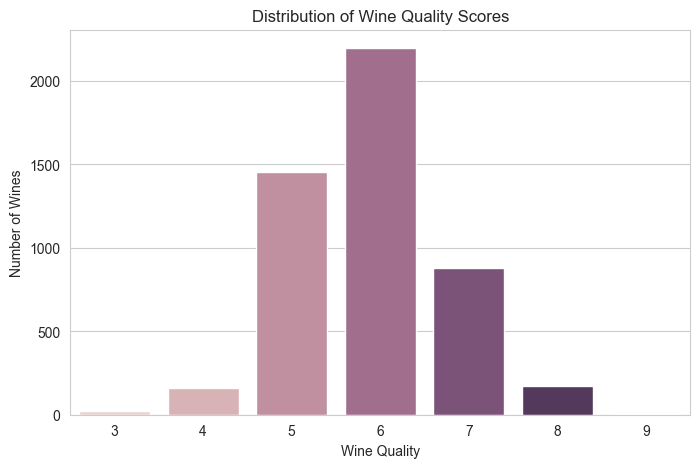

In [12]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='quality', hue='quality', legend=False)
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Wine Quality')
plt.ylabel('Number of Wines')
plt.show()

In [13]:
average_quality = df['quality'].mean()
print("Average Wine Quality:", round(average_quality, 2))

Average Wine Quality: 5.88


In [14]:
quality_percentage = (
    df['quality'].value_counts(normalize=True).sort_index() * 100
)
print("Quality Class Percentage:")
print(quality_percentage.round(2))

Quality Class Percentage:
quality
3     0.41
4     3.33
5    29.75
6    44.88
7    17.97
8     3.57
9     0.10
Name: proportion, dtype: float64


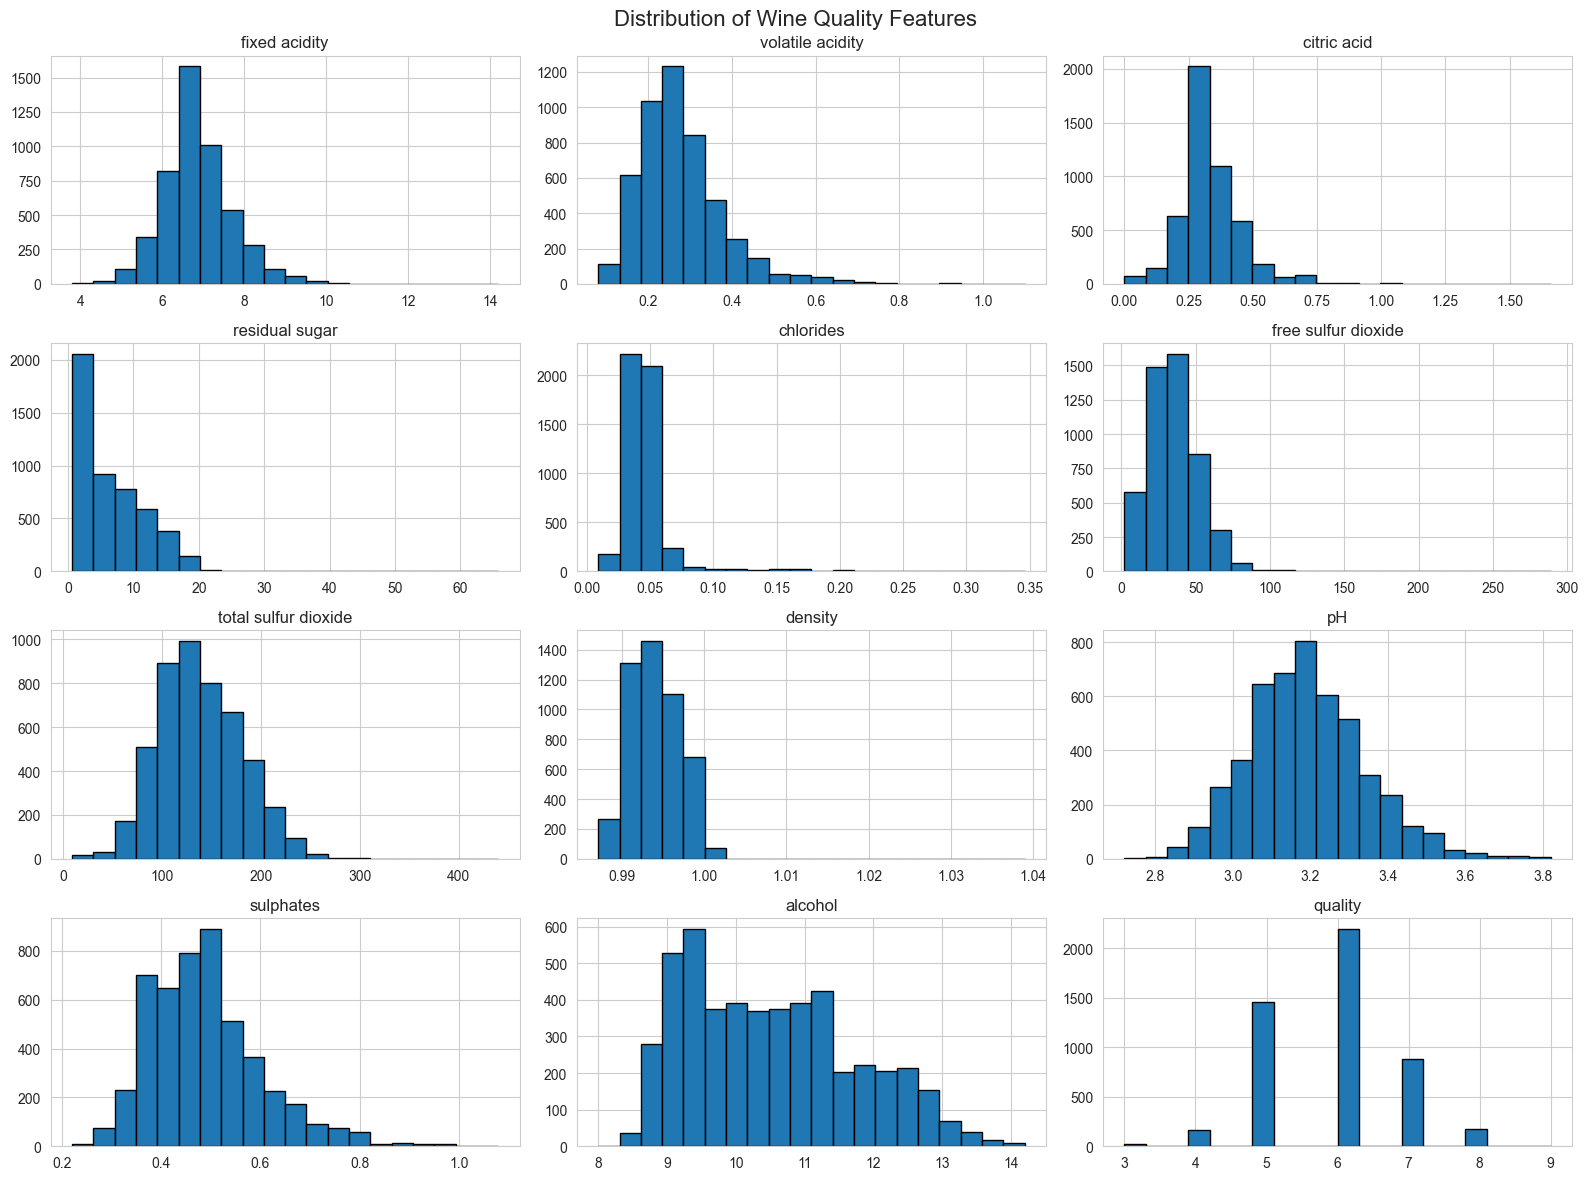

In [15]:
df.hist(figsize=(16, 12), bins=20, edgecolor='black')
plt.suptitle('Distribution of Wine Quality Features', fontsize=16)
plt.tight_layout()
plt.show()

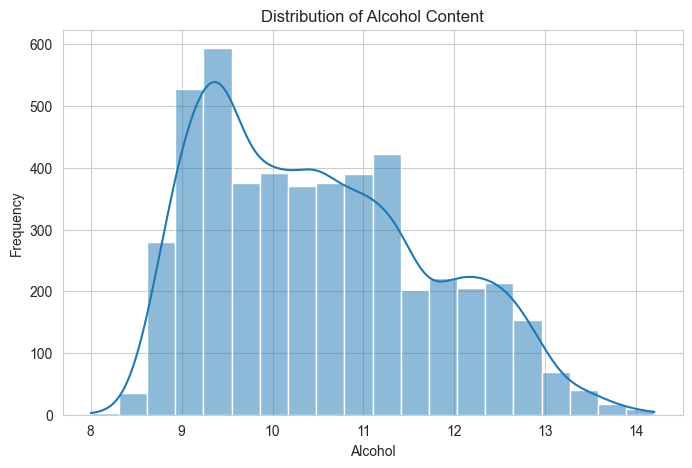

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(df['alcohol'], bins=20, kde=True)
plt.title('Distribution of Alcohol Content')
plt.xlabel('Alcohol')
plt.ylabel('Frequency')
plt.show()

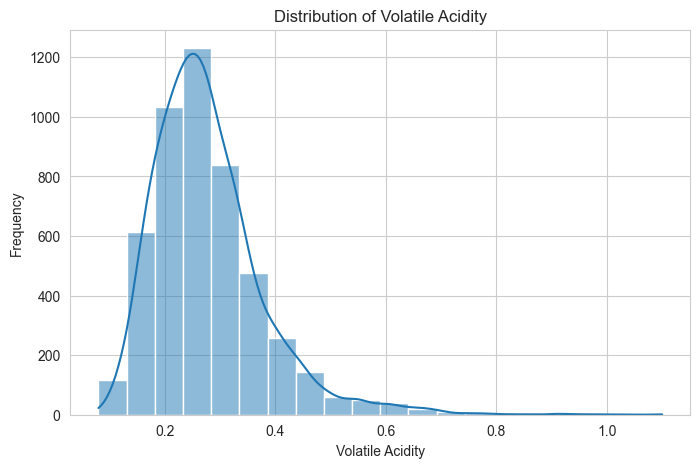

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(df['volatile acidity'], bins=20, kde=True)
plt.title('Distribution of Volatile Acidity')
plt.xlabel('Volatile Acidity')
plt.ylabel('Frequency')
plt.show()

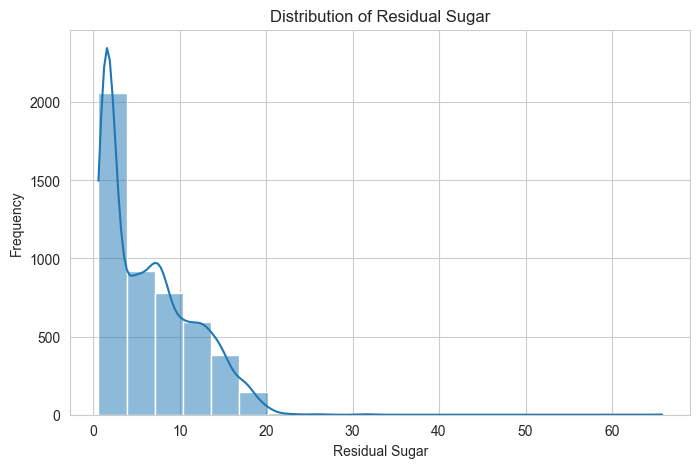

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(df['residual sugar'], bins=20, kde=True)
plt.title('Distribution of Residual Sugar')
plt.xlabel('Residual Sugar')
plt.ylabel('Frequency')
plt.show()

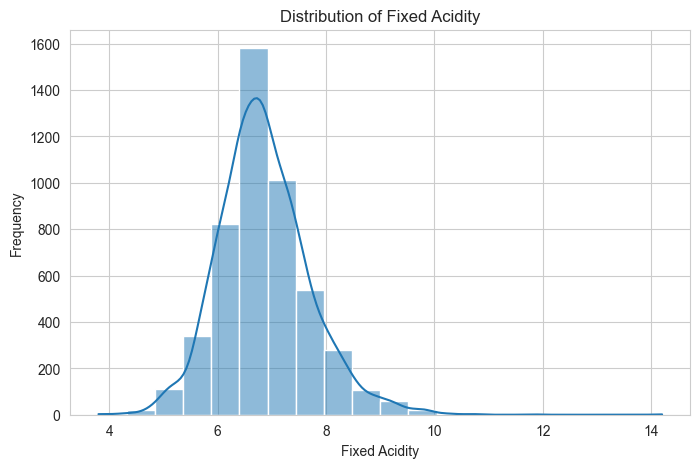

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(df['fixed acidity'], bins=20, kde=True)
plt.title('Distribution of Fixed Acidity')
plt.xlabel('Fixed Acidity')
plt.ylabel('Frequency')
plt.show()

In [20]:
correlation_matrix = df.corr()
correlation_matrix

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.022697,0.289181,0.089021,0.023086,-0.049396,0.091070,0.265331,-0.425858,-0.017143,-0.120881,-0.113663
volatile acidity,-0.022697,1.000000,-0.149472,0.064286,0.070512,-0.097012,0.089261,0.027114,-0.031915,-0.035728,0.067718,-0.194723
citric acid,0.289181,-0.149472,1.000000,0.094212,0.114364,0.094077,0.121131,0.149503,-0.163748,0.062331,-0.075729,-0.009209
residual sugar,0.089021,0.064286,0.094212,1.000000,0.088685,0.299098,0.401439,0.838966,-0.194133,-0.026664,-0.450631,-0.097577
chlorides,0.023086,0.070512,0.114364,0.088685,1.000000,0.101392,0.198910,0.257211,-0.090439,0.016763,-0.360189,-0.209934
free sulfur dioxide,-0.049396,-0.097012,0.094077,0.299098,0.101392,1.000000,0.615501,0.294210,-0.000618,0.059217,-0.250104,0.008158
total sulfur dioxide,0.091070,0.089261,0.121131,0.401439,0.198910,0.615501,1.000000,0.529881,0.002321,0.134562,-0.448892,-0.174737
density,0.265331,0.027114,0.149503,0.838966,0.257211,0.294210,0.529881,1.000000,-0.093591,0.074493,-0.780138,-0.307123
pH,-0.425858,-0.031915,-0.163748,-0.194133,-0.090439,-0.000618,0.002321,-0.093591,1.000000,0.155951,0.121432,0.099427
sulphates,-0.017143,-0.035728,0.062331,-0.026664,0.016763,0.059217,0.134562,0.074493,0.155951,1.000000,-0.017433,0.053678


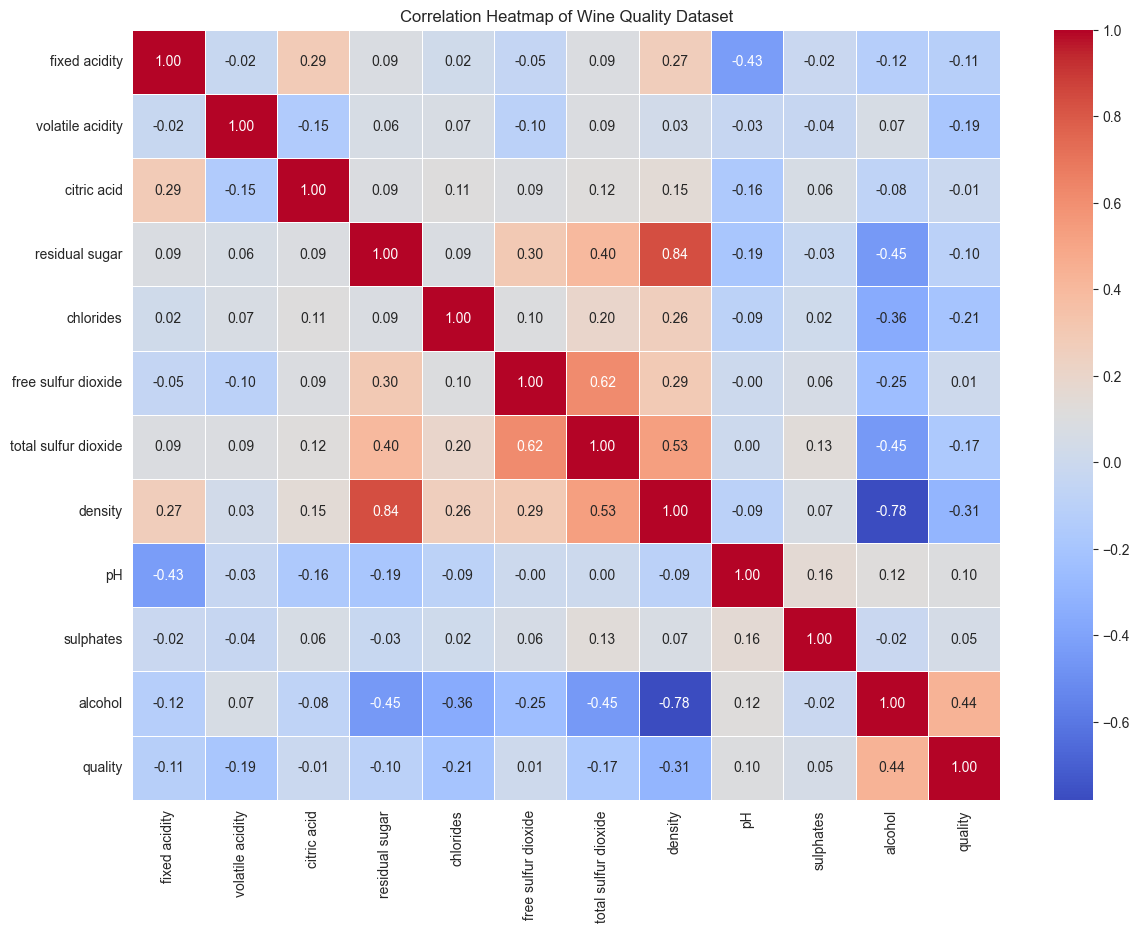

In [21]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of Wine Quality Dataset')
plt.show()

In [22]:
quality_correlation = correlation_matrix['quality'].sort_values(
    ascending=False
)
print("Correlation with Wine Quality:")
print(quality_correlation)

Correlation with Wine Quality:
quality                 1.000000
alcohol                 0.435575
pH                      0.099427
sulphates               0.053678
free sulfur dioxide     0.008158
citric acid            -0.009209
residual sugar         -0.097577
fixed acidity          -0.113663
total sulfur dioxide   -0.174737
volatile acidity       -0.194723
chlorides              -0.209934
density                -0.307123
Name: quality, dtype: float64


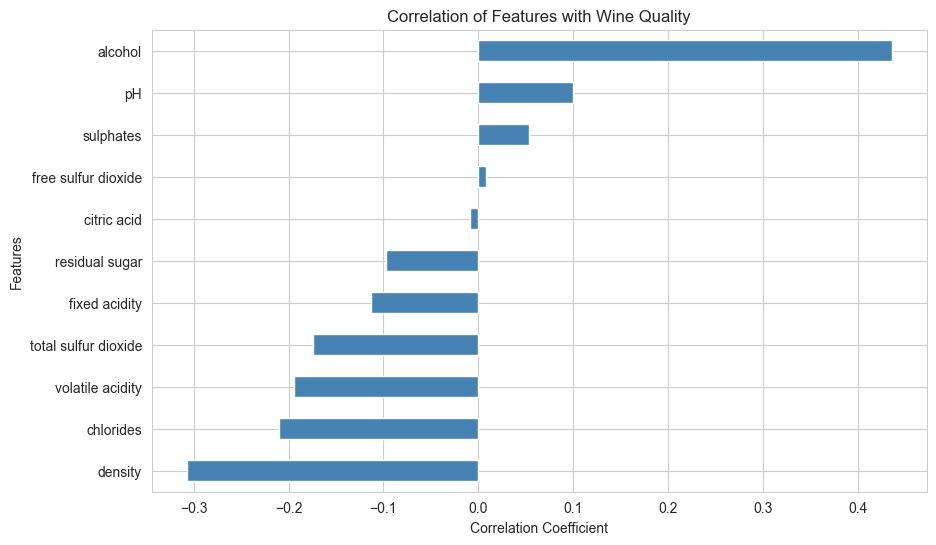

In [24]:
plt.figure(figsize=(10, 6))
quality_correlation.drop('quality').sort_values().plot(
    kind='barh',
    color='steelblue'
)
plt.title('Correlation of Features with Wine Quality')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.show()

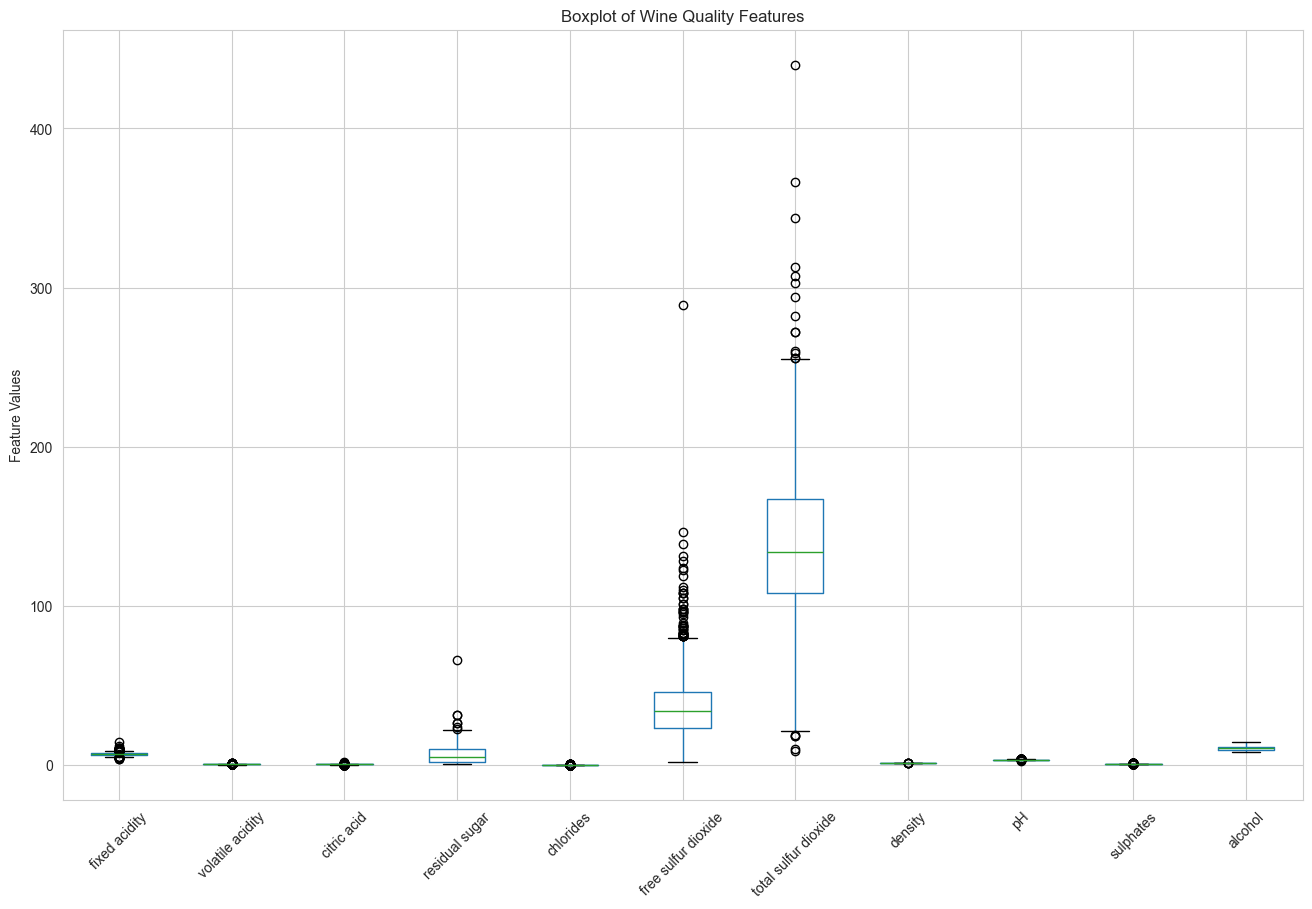

In [25]:
plt.figure(figsize=(16, 10))
df.drop(columns=['quality']).boxplot()
plt.title('Boxplot of Wine Quality Features')
plt.xticks(rotation=45)
plt.ylabel('Feature Values')
plt.show()

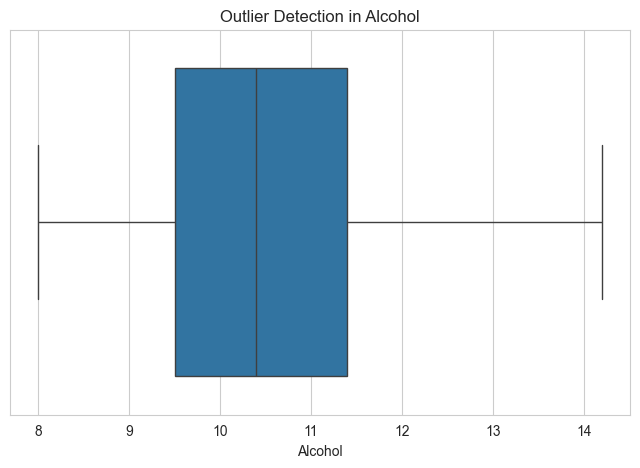

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['alcohol'])
plt.title('Outlier Detection in Alcohol')
plt.xlabel('Alcohol')
plt.show()

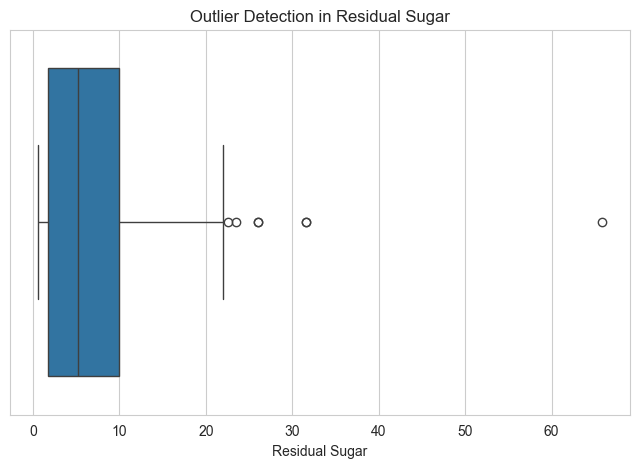

In [27]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['residual sugar'])
plt.title('Outlier Detection in Residual Sugar')
plt.xlabel('Residual Sugar')
plt.show()

In [28]:
Q1 = df.drop(columns=['quality']).quantile(0.25)
Q3 = df.drop(columns=['quality']).quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outlier_count = (
    (df.drop(columns=['quality']) < lower_bound) |
    (df.drop(columns=['quality']) > upper_bound)
).sum()
print("Outliers in Each Feature:")
print(outlier_count)

Outliers in Each Feature:
fixed acidity           119
volatile acidity        186
citric acid             270
residual sugar            7
chlorides               208
free sulfur dioxide      50
total sulfur dioxide     19
density                   5
pH                       75
sulphates               124
alcohol                   0
dtype: int64


In [29]:
df['good_quality'] = (df['quality'] >= 6).astype(int)
print("Binary Classification Created Successfully!")
print("\nGood and Bad Wine Counts:")
print(df['good_quality'].value_counts())

Binary Classification Created Successfully!

Good and Bad Wine Counts:
good_quality
1    3258
0    1640
Name: count, dtype: int64


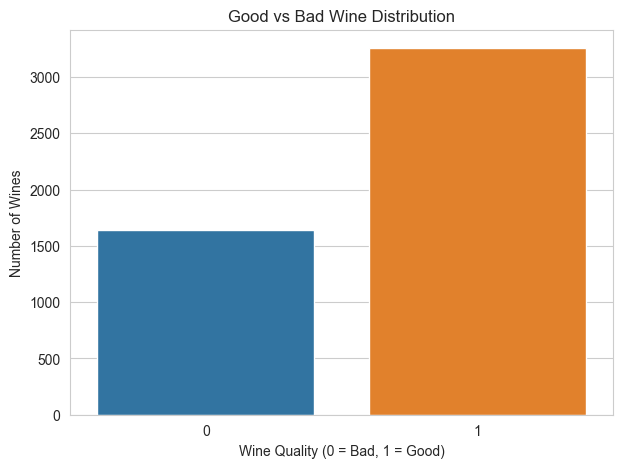

In [30]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='good_quality', hue='good_quality', legend=False)
plt.title('Good vs Bad Wine Distribution')
plt.xlabel('Wine Quality (0 = Bad, 1 = Good)')
plt.ylabel('Number of Wines')
plt.show()

In [31]:
def classify_quality(quality):
    if quality <= 4:
        return 0
    elif quality <= 6:
        return 1
    else:
        return 2
df['quality_class'] = df['quality'].apply(classify_quality)
print("Three-Class Classification Created Successfully!")
print("\nQuality Class Counts:")
print(df['quality_class'].value_counts().sort_index())

Three-Class Classification Created Successfully!

Quality Class Counts:
quality_class
0     183
1    3655
2    1060
Name: count, dtype: int64


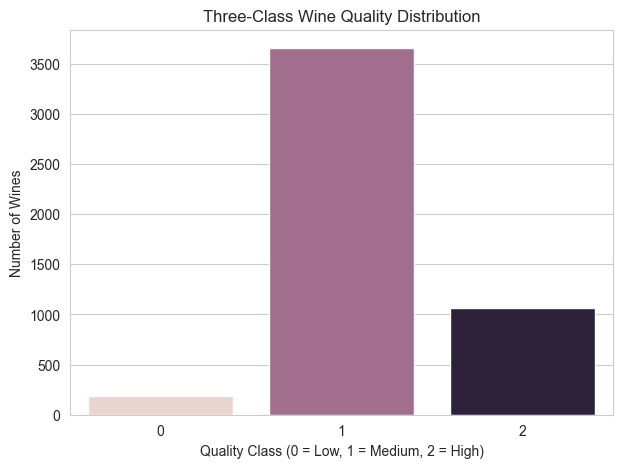

In [32]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='quality_class', hue='quality_class', legend=False)
plt.title('Three-Class Wine Quality Distribution')
plt.xlabel('Quality Class (0 = Low, 1 = Medium, 2 = High)')
plt.ylabel('Number of Wines')
plt.show()

In [33]:
df[['quality', 'good_quality', 'quality_class']].head(15)

,quality,good_quality,quality_class
0,6,1,1
1,6,1,1
2,6,1,1
3,6,1,1
4,6,1,1
5,6,1,1
6,6,1,1
7,6,1,1
8,6,1,1
9,6,1,1


In [34]:
X = df.drop(columns=['quality', 'good_quality', 'quality_class'])
print("Feature Matrix Shape:", X.shape)
X.head()

Feature Matrix Shape: (4898, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9


In [35]:
y_binary = df['good_quality']
print("Binary Target Shape:", y_binary.shape)
print("\nBinary Target Distribution:")
print(y_binary.value_counts())

Binary Target Shape: (4898,)

Binary Target Distribution:
good_quality
1    3258
0    1640
Name: count, dtype: int64


In [36]:
y_multi = df['quality_class']
print("Multi-Class Target Shape:", y_multi.shape)
print("\nMulti-Class Target Distribution:")
print(y_multi.value_counts().sort_index())

Multi-Class Target Shape: (4898,)

Multi-Class Target Distribution:
quality_class
0     183
1    3655
2    1060
Name: count, dtype: int64


In [37]:
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)
print("Binary Classification Dataset Split:")
print("Training Features:", X_train_bin.shape)
print("Testing Features:", X_test_bin.shape)
print("Training Target:", y_train_bin.shape)
print("Testing Target:", y_test_bin.shape)

Binary Classification Dataset Split:
Training Features: (3918, 11)
Testing Features: (980, 11)
Training Target: (3918,)
Testing Target: (980,)


In [38]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X,
    y_multi,
    test_size=0.20,
    random_state=42,
    stratify=y_multi
)
print("Multi-Class Classification Dataset Split:")
print("Training Features:", X_train_multi.shape)
print("Testing Features:", X_test_multi.shape)
print("Training Target:", y_train_multi.shape)
print("Testing Target:", y_test_multi.shape)

Multi-Class Classification Dataset Split:
Training Features: (3918, 11)
Testing Features: (980, 11)
Training Target: (3918,)
Testing Target: (980,)


In [39]:
scaler = StandardScaler()
X_train_bin_scaled = scaler.fit_transform(X_train_bin)
X_test_bin_scaled = scaler.transform(X_test_bin)
X_train_multi_scaled = scaler.fit_transform(X_train_multi)
X_test_multi_scaled = scaler.transform(X_test_multi)
print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [40]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train_bin, y_train_bin)
rf_multi_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_multi_model.fit(X_train_multi, y_train_multi)
print("Random Forest Models Trained Successfully!")

Random Forest Models Trained Successfully!


In [41]:
sgd_model = SGDClassifier(
    max_iter=1000,
    random_state=42
)
sgd_model.fit(X_train_bin_scaled, y_train_bin)
sgd_multi_model = SGDClassifier(
    max_iter=1000,
    random_state=42
)
sgd_multi_model.fit(X_train_multi_scaled, y_train_multi)
print("SGD Models Trained Successfully!")

SGD Models Trained Successfully!


In [42]:
svc_model = SVC(
    kernel='rbf',
    random_state=42
)
svc_model.fit(X_train_bin_scaled, y_train_bin)
svc_multi_model = SVC(
    kernel='rbf',
    random_state=42
)
svc_multi_model.fit(X_train_multi_scaled, y_train_multi)
print("SVC Models Trained Successfully!")

SVC Models Trained Successfully!


In [43]:
models = {
    "Random Forest - Binary": rf_model,
    "SGD - Binary": sgd_model,
    "SVC - Binary": svc_model,
    "Random Forest - Multi-Class": rf_multi_model,
    "SGD - Multi-Class": sgd_multi_model,
    "SVC - Multi-Class": svc_multi_model
}
for model_name, model in models.items():
    print(model_name, "-> Trained Successfully")

Random Forest - Binary -> Trained Successfully
SGD - Binary -> Trained Successfully
SVC - Binary -> Trained Successfully
Random Forest - Multi-Class -> Trained Successfully
SGD - Multi-Class -> Trained Successfully
SVC - Multi-Class -> Trained Successfully


In [44]:
rf_predictions = rf_model.predict(X_test_bin)
rf_multi_predictions = rf_multi_model.predict(X_test_multi)
print("Random Forest Predictions Completed!")
print("\nFirst 10 Binary Predictions:")
print(rf_predictions[:10])
print("\nFirst 10 Multi-Class Predictions:")
print(rf_multi_predictions[:10])

Random Forest Predictions Completed!

First 10 Binary Predictions:
[1 0 1 1 0 0 1 0 0 0]

First 10 Multi-Class Predictions:
[1 2 1 1 1 2 1 1 1 1]


In [45]:
sgd_predictions = sgd_model.predict(X_test_bin_scaled)
sgd_multi_predictions = sgd_multi_model.predict(X_test_multi_scaled)
print("SGD Predictions Completed!")
print("\nFirst 10 Binary Predictions:")
print(sgd_predictions[:10])
print("\nFirst 10 Multi-Class Predictions:")
print(sgd_multi_predictions[:10])

SGD Predictions Completed!

First 10 Binary Predictions:
[1 0 1 1 0 1 1 1 0 0]

First 10 Multi-Class Predictions:
[1 1 1 1 1 1 1 1 1 1]


In [46]:
svc_predictions = svc_model.predict(X_test_bin_scaled)
svc_multi_predictions = svc_multi_model.predict(X_test_multi_scaled)
print("SVC Predictions Completed!")
print("\nFirst 10 Binary Predictions:")
print(svc_predictions[:10])
print("\nFirst 10 Multi-Class Predictions:")
print(svc_multi_predictions[:10])

SVC Predictions Completed!

First 10 Binary Predictions:
[1 0 1 1 0 0 1 0 0 0]

First 10 Multi-Class Predictions:
[1 2 1 2 1 1 1 1 1 1]


In [47]:
print("BINARY CLASSIFICATION ACCURACY")
print("--------------------------------")
print("Random Forest:", accuracy_score(y_test_bin, rf_predictions))
print("SGD Classifier:", accuracy_score(y_test_bin, sgd_predictions))
print("SVC:", accuracy_score(y_test_bin, svc_predictions))
print("\nMULTI-CLASS CLASSIFICATION ACCURACY")
print("-----------------------------------")
print("Random Forest:", accuracy_score(y_test_multi, rf_multi_predictions))
print("SGD Classifier:", accuracy_score(y_test_multi, sgd_multi_predictions))
print("SVC:", accuracy_score(y_test_multi, svc_multi_predictions))

BINARY CLASSIFICATION ACCURACY
--------------------------------
Random Forest: 0.8387755102040816
SGD Classifier: 0.7285714285714285
SVC: 0.7744897959183673

MULTI-CLASS CLASSIFICATION ACCURACY
-----------------------------------
Random Forest: 0.8510204081632653
SGD Classifier: 0.7489795918367347
SVC: 0.8010204081632653


In [48]:
print("RANDOM FOREST REPORT")
print(classification_report(y_test_bin, rf_predictions))
print("\nSGD CLASSIFIER REPORT")
print(classification_report(y_test_bin, sgd_predictions))
print("\nSVC REPORT")
print(classification_report(y_test_bin, svc_predictions))

RANDOM FOREST REPORT
              precision    recall  f1-score   support

           0       0.78      0.73      0.75       328
           1       0.87      0.89      0.88       652

    accuracy                           0.84       980
   macro avg       0.82      0.81      0.82       980
weighted avg       0.84      0.84      0.84       980


SGD CLASSIFIER REPORT
              precision    recall  f1-score   support

           0       0.60      0.56      0.58       328
           1       0.79      0.81      0.80       652

    accuracy                           0.73       980
   macro avg       0.69      0.69      0.69       980
weighted avg       0.72      0.73      0.73       980


SVC REPORT
              precision    recall  f1-score   support

           0       0.68      0.62      0.65       328
           1       0.82      0.85      0.83       652

    accuracy                           0.77       980
   macro avg       0.75      0.74      0.74       980
weighted avg      

In [49]:
print("RANDOM FOREST REPORT")
print(classification_report(y_test_multi, rf_multi_predictions))
print("\nSGD CLASSIFIER REPORT")
print(classification_report(y_test_multi, sgd_multi_predictions))
print("\nSVC REPORT")
print(classification_report(y_test_multi, svc_multi_predictions))

RANDOM FOREST REPORT
              precision    recall  f1-score   support

           0       0.58      0.19      0.29        37
           1       0.87      0.95      0.91       731
           2       0.79      0.64      0.71       212

    accuracy                           0.85       980
   macro avg       0.75      0.59      0.63       980
weighted avg       0.84      0.85      0.84       980


SGD CLASSIFIER REPORT
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        37
           1       0.76      0.97      0.85       731
           2       0.53      0.13      0.21       212

    accuracy                           0.75       980
   macro avg       0.43      0.37      0.35       980
weighted avg       0.68      0.75      0.68       980


SVC REPORT
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        37
           1       0.81      0.96      0.88       731
           2       

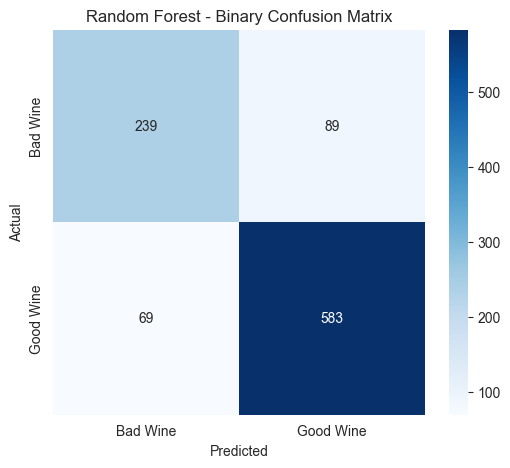

In [50]:
cm_rf = confusion_matrix(y_test_bin, rf_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Bad Wine', 'Good Wine'],
    yticklabels=['Bad Wine', 'Good Wine']
)
plt.title('Random Forest - Binary Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

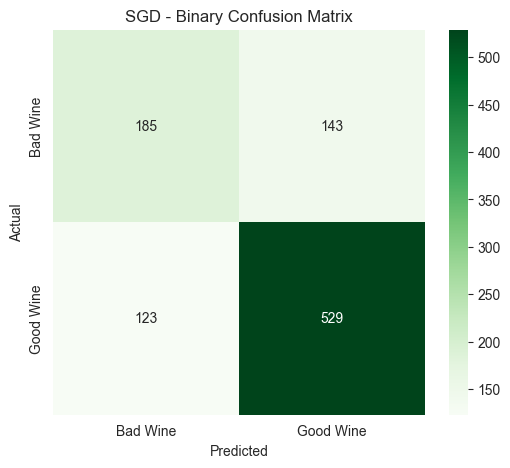

In [51]:
cm_sgd = confusion_matrix(y_test_bin, sgd_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_sgd,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Bad Wine', 'Good Wine'],
    yticklabels=['Bad Wine', 'Good Wine']
)
plt.title('SGD - Binary Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

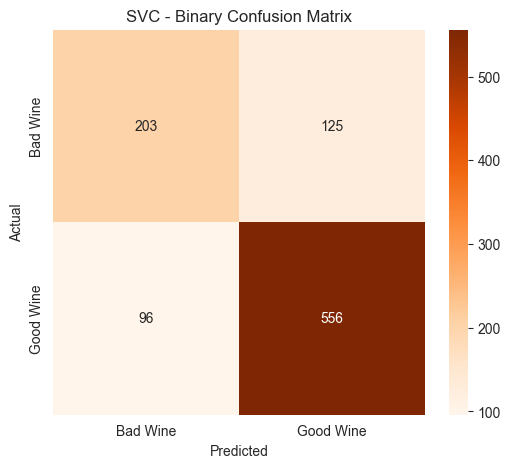

In [52]:
cm_svc = confusion_matrix(y_test_bin, svc_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_svc,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Bad Wine', 'Good Wine'],
    yticklabels=['Bad Wine', 'Good Wine']
)
plt.title('SVC - Binary Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

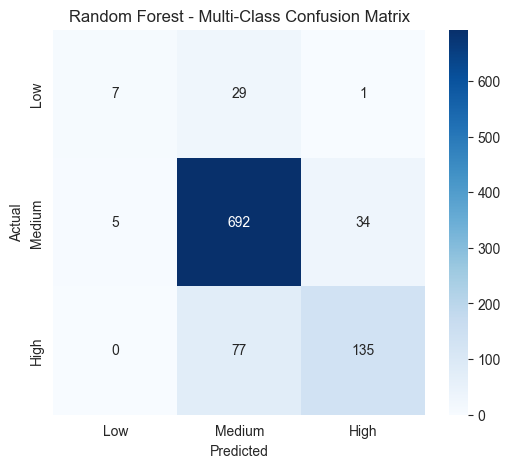

In [53]:
cm_rf_multi = confusion_matrix(
    y_test_multi,
    rf_multi_predictions,
    labels=[0, 1, 2]
)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf_multi,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)
plt.title('Random Forest - Multi-Class Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

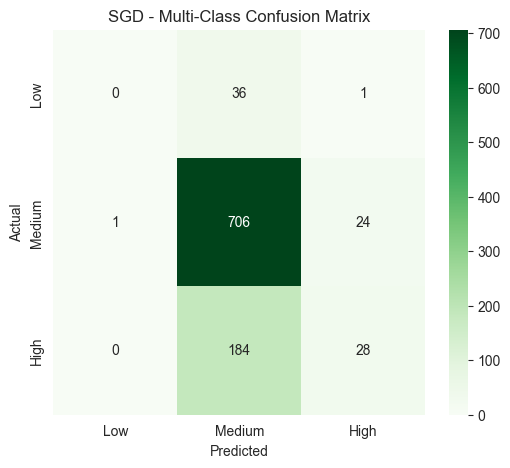

In [54]:
cm_sgd_multi = confusion_matrix(
    y_test_multi,
    sgd_multi_predictions,
    labels=[0, 1, 2]
)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_sgd_multi,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)
plt.title('SGD - Multi-Class Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

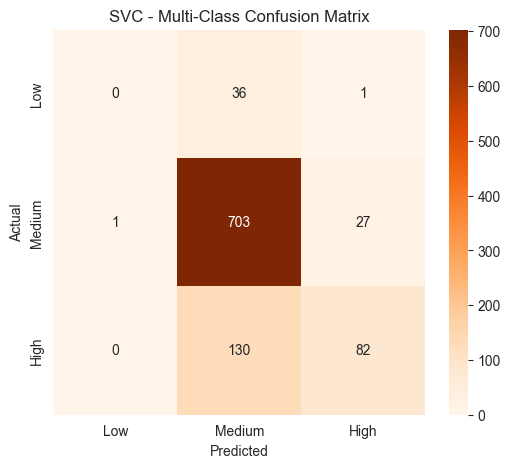

In [55]:
cm_svc_multi = confusion_matrix(
    y_test_multi,
    svc_multi_predictions,
    labels=[0, 1, 2]
)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_svc_multi,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)
plt.title('SVC - Multi-Class Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [56]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)
print("Random Forest Feature Importance:")
print(feature_importance)

Random Forest Feature Importance:
                 Feature  Importance
10               alcohol    0.147048
1       volatile acidity    0.120319
7                density    0.110200
5    free sulfur dioxide    0.094483
6   total sulfur dioxide    0.083381
3         residual sugar    0.080983
4              chlorides    0.080324
2            citric acid    0.079892
8                     pH    0.071212
0          fixed acidity    0.067471
9              sulphates    0.064687


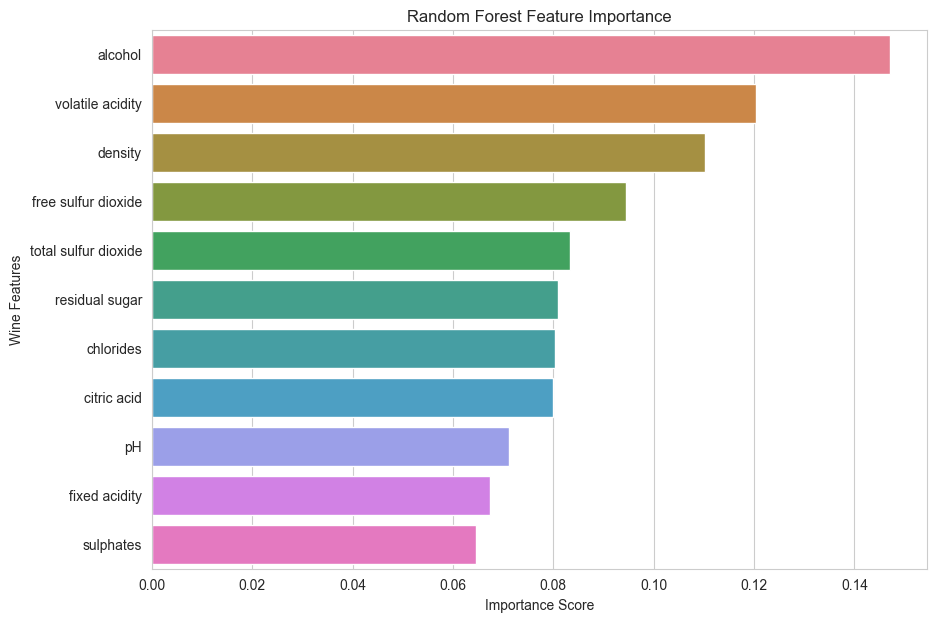

In [57]:
plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False
)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Wine Features')
plt.show()

In [58]:
top_5_features = feature_importance.head(5)
print("Top 5 Important Features:")
print(top_5_features)

Top 5 Important Features:
                 Feature  Importance
10               alcohol    0.147048
1       volatile acidity    0.120319
7                density    0.110200
5    free sulfur dioxide    0.094483
6   total sulfur dioxide    0.083381


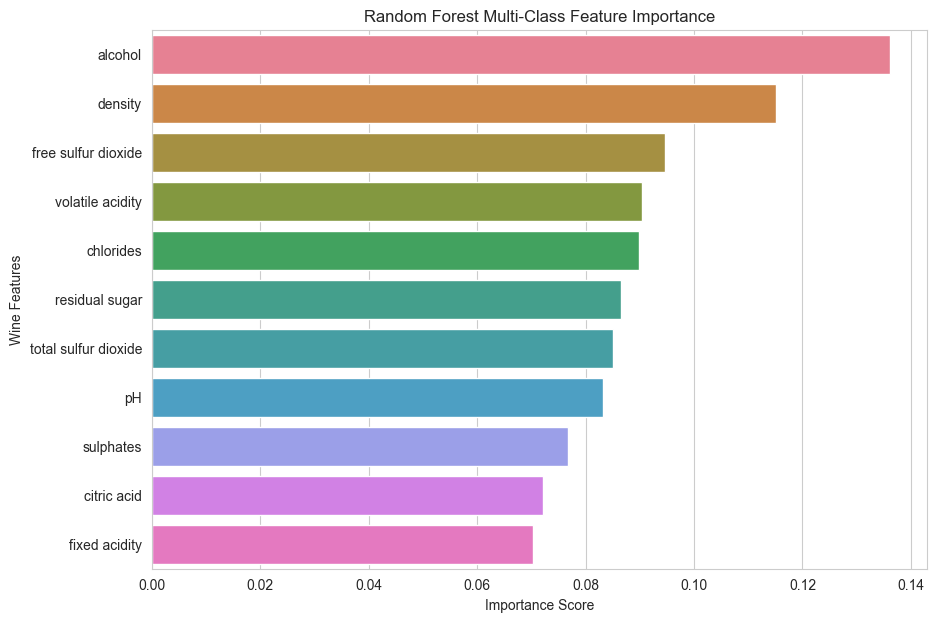

In [59]:
multi_feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_multi_model.feature_importances_
})
multi_feature_importance = multi_feature_importance.sort_values(
    by='Importance',
    ascending=False
)
plt.figure(figsize=(10, 7))
sns.barplot(
    data=multi_feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False
)
plt.title('Random Forest Multi-Class Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Wine Features')
plt.show()

In [60]:
model_comparison = pd.DataFrame({
    'Model': [
        'Random Forest (Binary)',
        'SGD (Binary)',
        'SVC (Binary)',
        'Random Forest (Multi-Class)',
        'SGD (Multi-Class)',
        'SVC (Multi-Class)'
    ],

    'Accuracy': [
        accuracy_score(y_test_bin, rf_predictions),
        accuracy_score(y_test_bin, sgd_predictions),
        accuracy_score(y_test_bin, svc_predictions),
        accuracy_score(y_test_multi, rf_multi_predictions),
        accuracy_score(y_test_multi, sgd_multi_predictions),
        accuracy_score(y_test_multi, svc_multi_predictions)
    ],

    'F1 Score': [
        classification_report(y_test_bin, rf_predictions, output_dict=True)['weighted avg']['f1-score'],
        classification_report(y_test_bin, sgd_predictions, output_dict=True)['weighted avg']['f1-score'],
        classification_report(y_test_bin, svc_predictions, output_dict=True)['weighted avg']['f1-score'],
        classification_report(y_test_multi, rf_multi_predictions, output_dict=True)['weighted avg']['f1-score'],
        classification_report(y_test_multi, sgd_multi_predictions, output_dict=True)['weighted avg']['f1-score'],
        classification_report(y_test_multi, svc_multi_predictions, output_dict=True)['weighted avg']['f1-score']
    ]
})
model_comparison = model_comparison.sort_values(
    by='Accuracy',
    ascending=False
)
model_comparison

,Model,Accuracy,F1 Score
3,Random Forest (Multi-Class),0.851020,0.838869
0,Random Forest (Binary),0.838776,0.837458
5,SVC (Multi-Class),0.801020,0.765654
2,SVC (Binary),0.774490,0.771728
4,SGD (Multi-Class),0.748980,0.681343
1,SGD (Binary),0.728571,0.726354


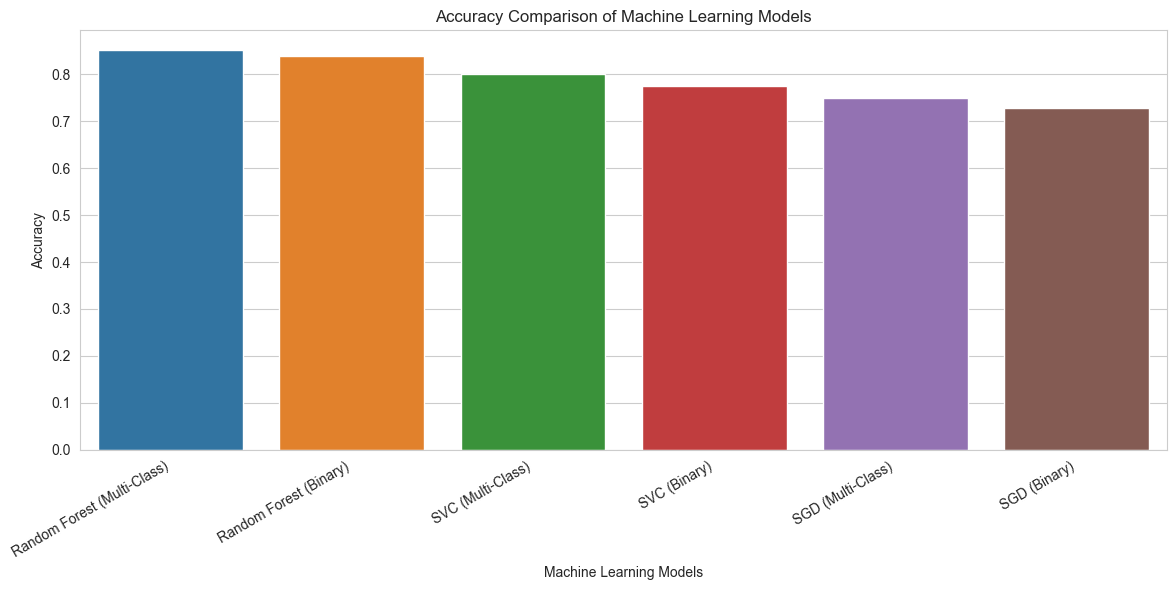

In [61]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy',
    hue='Model',
    legend=False
)
plt.title('Accuracy Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

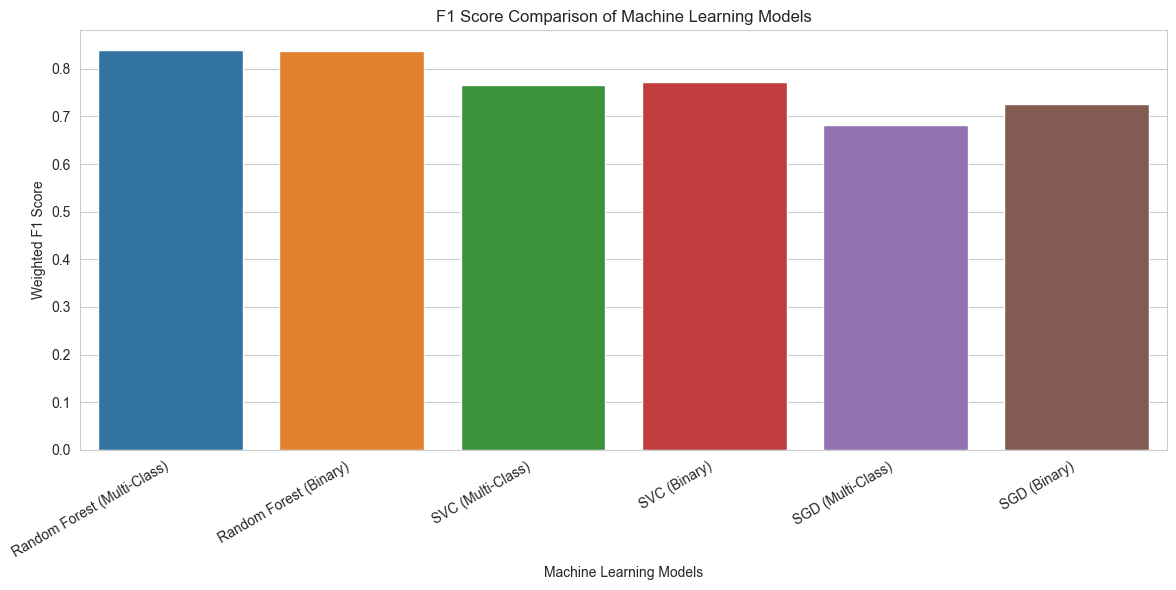

In [62]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=model_comparison,
    x='Model',
    y='F1 Score',
    hue='Model',
    legend=False
)
plt.title('F1 Score Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Weighted F1 Score')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [63]:
best_model = model_comparison.iloc[0]
print("BEST PERFORMING MODEL")
print("---------------------")
print("Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")
print("Weighted F1 Score:", round(best_model['F1 Score'], 4))

BEST PERFORMING MODEL
---------------------
Model: Random Forest (Multi-Class)
Accuracy: 85.1 %
Weighted F1 Score: 0.8389


In [64]:
sample_wine = X_test_bin.iloc[[0]]
prediction = rf_model.predict(sample_wine)
if prediction[0] == 1:
    print("Prediction: Good Quality Wine")
else:
    print("Prediction: Bad Quality Wine")
print("\nActual Quality:", y_test_bin.iloc[0])

Prediction: Good Quality Wine

Actual Quality: 1


In [65]:
prediction_results = pd.DataFrame({
    'Actual': y_test_bin.iloc[:15].values,
    'Predicted': rf_predictions[:15]
})
prediction_results

,Actual,Predicted
0,1,1
1,0,0
2,1,1
3,1,1
4,0,0
5,0,0
6,1,1
7,0,0
8,0,0
9,0,0


In [66]:
custom_wine = pd.DataFrame([{
    'fixed acidity': 7.0,
    'volatile acidity': 0.27,
    'citric acid': 0.36,
    'residual sugar': 20.7,
    'chlorides': 0.045,
    'free sulfur dioxide': 45.0,
    'total sulfur dioxide': 170.0,
    'density': 1.001,
    'pH': 3.0,
    'sulphates': 0.45,
    'alcohol': 8.8
}])
custom_prediction = rf_model.predict(custom_wine)
print("Custom Wine Prediction:")
if custom_prediction[0] == 1:
    print("Good Quality Wine")
else:
    print("Bad Quality Wine")

Custom Wine Prediction:
Good Quality Wine


In [67]:
import joblib
print("Joblib Imported Successfully!")

Joblib Imported Successfully!


In [68]:
joblib.dump(rf_model, 'random_forest_binary.pkl')
joblib.dump(sgd_model, 'sgd_binary.pkl')
joblib.dump(svc_model, 'svc_binary.pkl')
joblib.dump(rf_multi_model, 'random_forest_multiclass.pkl')
joblib.dump(sgd_multi_model, 'sgd_multiclass.pkl')
joblib.dump(svc_multi_model, 'svc_multiclass.pkl')
joblib.dump(scaler, 'standard_scaler.pkl')
print("All Models and Scaler Saved Successfully!")

All Models and Scaler Saved Successfully!


In [69]:
loaded_model = joblib.load('random_forest_binary.pkl')
loaded_prediction = loaded_model.predict(sample_wine)
print("Loaded Model Prediction:", loaded_prediction[0])
print("Original Model Prediction:", prediction[0])

Loaded Model Prediction: 1
Original Model Prediction: 1


# Conclusion

The Wine Quality Prediction project successfully demonstrates
the application of machine learning classification algorithms
to predict wine quality using physicochemical properties.

Three machine learning algorithms were implemented:

1. Random Forest Classifier
2. Stochastic Gradient Descent (SGD) Classifier
3. Support Vector Classifier (SVC)

Both binary classification and three-class classification
approaches were implemented.

Exploratory Data Analysis was performed to understand the
dataset, feature distributions, correlations, class imbalance,
and outliers.

The models were evaluated using accuracy, precision, recall,
F1-score, and confusion matrices.

Random Forest feature importance was also analyzed to identify
the most influential chemical properties.

Finally, the models were compared to identify the best-performing
approach for wine quality prediction.

This project demonstrates how machine learning can help
analyze wine characteristics and predict quality categories.